# DS203 Project - Preprocessing

1. load data, add region
2. log transform + missing flags
3. stratified train/val/test split
4. preprocessing pipeline (impute, scale, encode)
5. PCA

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA

## 1. Load data and add region

In [ ]:
df = pd.read_csv("DS203_final_dataset.csv")

short_names = {
    "NY.GDP.MKTP.KD.ZG": "gdp_growth",
    "FP.CPI.TOTL.ZG": "inflation",
    "SL.UEM.TOTL.ZS": "unemployment",
    "SP.DYN.IMRT.IN": "infant_mortality",
    "EG.ELC.ACCS.ZS": "electricity",
    "IT.NET.USER.ZS": "internet",
    "NV.AGR.TOTL.ZS": "agriculture",
    "NV.IND.TOTL.ZS": "industry",
    "NE.TRD.GNFS.ZS": "trade",
}
for code_name, short in short_names.items():
    df[short] = df[code_name]
    df = df.drop(columns=[code_name, code_name + "_year"])

df["y"] = df["y"].astype(int)
class_names = ["Low", "Medium/High", "Very High"]

# region, same as the EDA notebook
resp = requests.get("https://api.worldbank.org/v2/country", params={"format": "json", "per_page": 300})
records = resp.json()[1]
region_lookup = {}
for rec in records:
    if rec["region"]["value"].strip() != "Aggregates":
        region_lookup[rec["id"]] = rec["region"]["value"].strip()
df["region"] = df["country_code"].map(region_lookup)

print("shape:", df.shape, " missing region:", df["region"].isnull().sum())
#df.head()

shape: (193, 15)  missing region: 0


## 2. Log transform + missing flags

From the EDA: trade, infant_mortality, unemployment and inflation have long right tails, so use `log(x+1)`.
Inflation has 2 negative values (deflation) - `log` doesn't work there, so those get set to 0 first
(fixed rule, not learned from data, so no leakage from doing it before the split).

In [ ]:
df["log_trade"] = np.log(df["trade"] + 1)
df["log_infant_mortality"] = np.log(df["infant_mortality"] + 1)
df["log_unemployment"] = np.log(df["unemployment"] + 1)

# fix the 2 negative inflation values before taking the log
inflation_fixed = df["inflation"].copy()
inflation_fixed.loc[inflation_fixed < 0] = 0
df["log_inflation"] = np.log(inflation_fixed + 1)

df[["log_trade", "log_infant_mortality", "log_unemployment", "log_inflation"]].describe()

,log_trade,log_infant_mortality,log_unemployment,log_inflation
count,170.000000,191.000000,179.000000,178.000000
mean,4.385365,2.622958,1.857634,2.002542
std,0.604728,0.928278,0.636317,0.858758
min,1.245229,0.832909,0.122218,0.000000
25%,3.956203,1.808154,1.423331,1.527213
50%,4.420167,2.653242,1.821965,1.926787
75%,4.765511,3.435598,2.251175,2.334790
max,6.000342,4.289089,3.572626,5.404215


Missing flags: for the 4 columns with the most gaps (trade, inflation, unemployment, internet),
add a 0/1 column marking whether the value was missing. Whether these actually help gets checked below with CV.

In [ ]:
flag_cols = []
for col in ["trade", "inflation", "unemployment", "internet"]:
    df[col + "_missing"] = df[col].isnull().astype(int)
    flag_cols.append(col + "_missing")

df[flag_cols].sum()

trade_missing           23
inflation_missing       15
unemployment_missing    14
internet_missing        11
dtype: int64

In [ ]:
num_cols = ["gdp_growth", "log_inflation", "log_unemployment", "log_infant_mortality",
            "electricity", "internet", "agriculture", "industry", "log_trade"]
cat_cols = ["region", "DominantSector"]

print("numerical:", len(num_cols), "categorical:", len(cat_cols), "flags:", len(flag_cols))

numerical: 9 categorical: 2 flags: 4


## 3. given train/val/test split (60/20/20)

Each row is a different country, so a random split is fine. `stratify=y` keeps the class proportions
the same in each part - matters since Low only has 26 countries. seed = 42.

In [ ]:
X = df[num_cols + cat_cols + flag_cols]
y = df["y"]

# 60/20/20: first split off 40%, then cut that 40% in half
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42)

#print("train:", X_train.shape, "val:", X_val.shape, "test:", X_test.shape)

In [ ]:
split_counts = pd.DataFrame({
    "train": y_train.value_counts().sort_index(),
    "val": y_val.value_counts().sort_index(),
    "test": y_test.value_counts().sort_index(),
})
split_counts.index = class_names
print(split_counts)
#print(split_counts / split_counts.sum() * 100)  # was checking the class % matched across splits

             train  val  test
Low             16    5     5
Medium/High     55   19    19
Very High       44   15    15


In [ ]:
# save which split each country is in, so the training notebook uses the same rows
df["split"] = "train"
df.loc[X_val.index, "split"] = "validation"
df.loc[X_test.index, "split"] = "test"

keep_cols = ["country_code", "country", "hdi_2023", "y", "split"] + num_cols + cat_cols + flag_cols
df[keep_cols].to_csv("DS203_model_data.csv", index=False)
print("saved DS203_model_data.csv", df[keep_cols].shape)
df["split"].value_counts()

saved DS203_model_data.csv (193, 20)


split
train         115
test           39
validation     39
Name: count, dtype: int64

## 4. Preprocessing pipeline

Numerical: impute (mean/median) then scale. Categorical: impute then one-hot encode.
Same `ColumnTransformer` + `Pipeline` pattern used in the sklearn pipeline notes.

In [ ]:
def preprocessor_banana(num_strategy, cat_strategy, use_flags):
    num_list = num_cols.copy()
    if use_flags:
        num_list = num_list + flag_cols

    numeric_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy=num_strategy)),
        ("scaler", StandardScaler())
    ])

    if cat_strategy == "Missing":
        cat_imputer = SimpleImputer(strategy="constant", fill_value="Missing")
    else:
        cat_imputer = SimpleImputer(strategy="most_frequent")

    categorical_transformer = Pipeline(steps=[
        ("imputer", cat_imputer),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocessor = ColumnTransformer(transformers=[
        ("num", numeric_transformer, num_list),
        ("cat", categorical_transformer, cat_cols)
    ])
    return preprocessor

### 4.1 Comparing imputation choices

Plain logistic regression, 5-fold CV, macro F1 - just to see if the choice of imputation/flags matters.

In [ ]:
results = []
for num_strategy in ["mean", "median"]:
    for cat_strategy in ["Missing", "most_frequent"]:
        for use_flags in [False, True]:
            pipe = Pipeline(steps=[
                ("prep", preprocessor_banana(num_strategy, cat_strategy, use_flags)),
                ("model", LogisticRegression(max_iter=1000))
            ])
            scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring="f1_macro")
            results.append([num_strategy, cat_strategy, use_flags, scores.mean(), scores.std()])
            #print(num_strategy, cat_strategy, use_flags, scores.mean())  # checking as it ran

impute_table = pd.DataFrame(results, columns=["num_strategy", "cat_strategy", "flags", "mean_f1", "std_f1"])
impute_table.round(3).sort_values("mean_f1", ascending=False)

,num_strategy,cat_strategy,flags,mean_f1,std_f1
2,mean,most_frequent,False,0.831,0.068
0,mean,Missing,False,0.824,0.059
6,median,most_frequent,False,0.824,0.059
4,median,Missing,False,0.824,0.059
5,median,Missing,True,0.817,0.051
7,median,most_frequent,True,0.817,0.051
3,mean,most_frequent,True,0.811,0.062
1,mean,Missing,True,0.811,0.062


All combinations land in a similar range. Going with median imputation, "Missing" as its own
category, and no flags (the flags didn't consistently help).

In [ ]:
prep = preprocessor_banana("median", "Missing", False)
prep.fit(X_train)  # fit on training data only

X_train_prep = prep.transform(X_train)
X_val_prep = prep.transform(X_val)
X_test_prep = prep.transform(X_test)
print("after preprocessing:", X_train_prep.shape, X_val_prep.shape, X_test_prep.shape)

feature_names = prep.get_feature_names_out()
feature_names = [f.replace("num__", "").replace("cat__", "") for f in feature_names]
print(feature_names)

after preprocessing: (115, 20) (39, 20) (39, 20)
['gdp_growth', 'log_inflation', 'log_unemployment', 'log_infant_mortality', 'electricity', 'internet', 'agriculture', 'industry', 'log_trade', 'region_East Asia & Pacific', 'region_Europe & Central Asia', 'region_Latin America & Caribbean', 'region_Middle East, North Africa, Afghanistan & Pakistan', 'region_North America', 'region_South Asia', 'region_Sub-Saharan Africa', 'DominantSector_Agriculture', 'DominantSector_Industry', 'DominantSector_Missing', 'DominantSector_Services']


## 5. PCA

fitted on the scaled/encoded training features only.

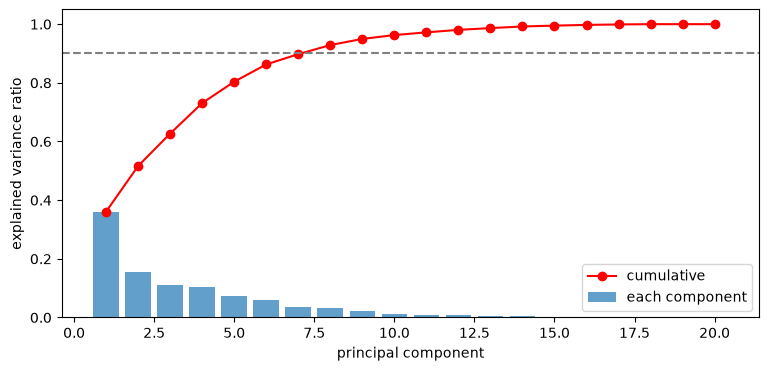

components needed for 90%: 8


In [ ]:
pca = PCA()
pca.fit(X_train_prep)

explained = pca.explained_variance_ratio_
cumulative = np.cumsum(explained)

plt.figure(figsize=(9, 4))
plt.bar(range(1, len(explained) + 1), explained, alpha=0.7, label="each component")
plt.plot(range(1, len(explained) + 1), cumulative, "ro-", label="cumulative")
plt.axhline(0.9, color="grey", linestyle="--")
plt.xlabel("principal component")
plt.ylabel("explained variance ratio")
plt.legend()
plt.show()

print("components needed for 90%:", np.argmax(cumulative >= 0.9) + 1)

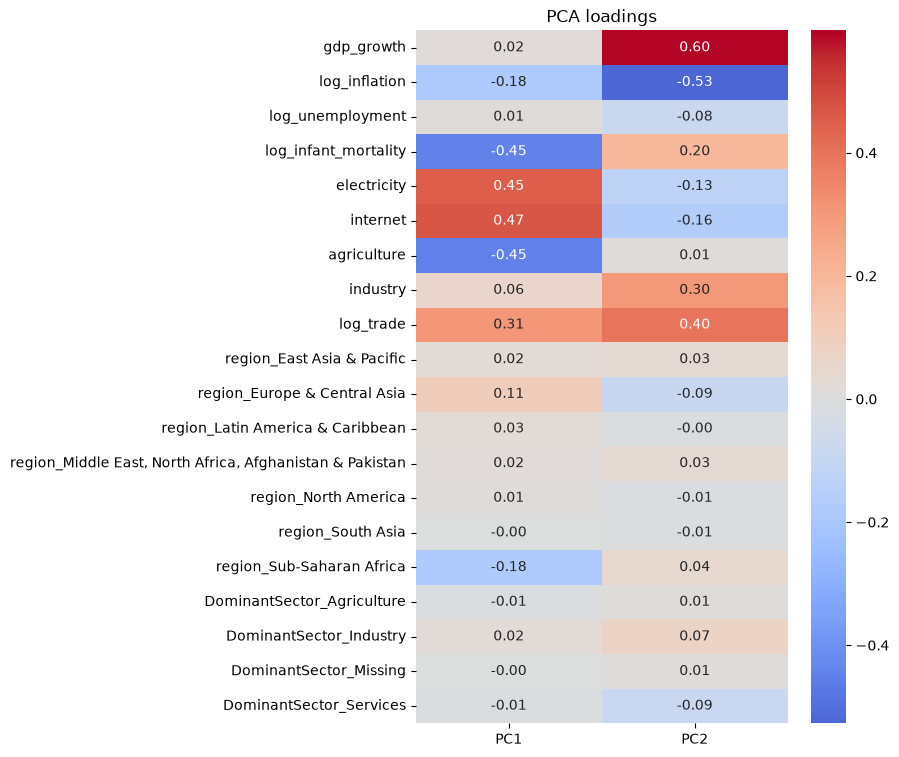

In [ ]:
# how much each original feature contributes to the first 2 components
loadings = pd.DataFrame(pca.components_[:2].T, index=feature_names, columns=["PC1", "PC2"])

plt.figure(figsize=(6, 9))
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("PCA loadings")
plt.show()

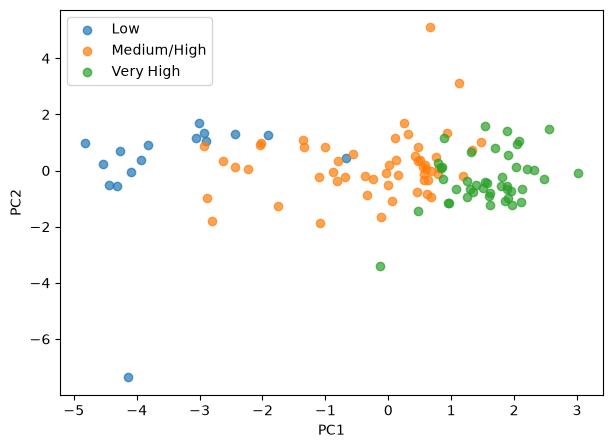

In [ ]:
X_train_pc = pca.transform(X_train_prep)

plt.figure(figsize=(7, 5))
for k in range(3):
    mask = (y_train.values == k)
    plt.scatter(X_train_pc[mask, 0], X_train_pc[mask, 1], label=class_names[k], alpha=0.7)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()
plt.show()

PC1 picks up the infant_mortality / electricity / internet / agriculture group that move together -
already seen in the EDA correlation heatmap. Classes aren't fully separated on PC1/PC2 alone, but
Low countries sit mostly on one side.